# Cascading of Tipping Events

As we have a feature for temporal correlation within a shift cluster, we can now think of ways on how to mimic local cascading events!

[Fig 1 of this puplication](https://link.springer.com/article/10.1007/s10712-024-09866-4/figures/1) suggests several tipping events that trigger each other or are simlutaneously triggered by an external event/forcing.

Idea-Pool:
- within a cluster mask, use Voronoi-Cells to distinguish tipping regions
- within each region, a shift event happens at a given time-offset
- neighbouring cells trigger each other -> shift moves stepwise through the whole cluster
- where is the first event? maybe different modes like central, boundaries, random
- fuzzy-up the edges to make it more natural


## Split up Mask in Voronoi Cells

In [35]:
from ponds import ELLIPSIS

lat_size = 10
lon_size = 10
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)

mask_gen = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=30,
    ecc_lon=150,
    )
mask = mask_gen.make_shape(lats, lons)

print(mask)

[[False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False  True  True  True  True  True  True  True  True False]
 [False  True  True  True  True  True  True  True  True False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]]


In [40]:
def make_time_offsets(
        shape_mask,
        n_cells,
        max_offset=5,
        corr_seed=1,
):
    latmin_ix, latmax_ix = np.where(np.any(shape_mask, axis=1))[0][[0, -1]]
    lonmin_ix, lonmax_ix = np.where(np.any(shape_mask, axis=0))[0][[0, -1]]
    #print(latmin_ix, latmax_ix, lonmin_ix, lonmax_ix)
    for i in range(n_cells):
        sx = ...

In [41]:
make_time_offsets(
    shape_mask=mask,
    n_cells=5,
)

## GiGi's Approach

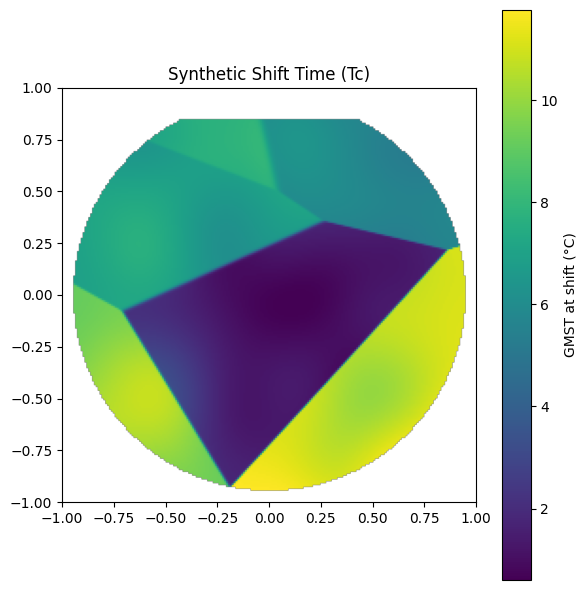

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Synthetic "shift landscape" generator for TOAD testing
# Produces a 3D dataset (y, x, gmst) with adjacent regions tipping at different forcings
# and smooth transitions between regions. 
#
# Design choices:
# - gmst axis (0..14 °C) acts as the control parameter (like the colorbar in the example)
# - Regional heterogeneity is encoded as a smooth field of local thresholds Tc(y,x)
#   created by blending Voronoi-like regions with soft boundaries + additional
#   Gaussian-correlated texture via FFT filtering.
# - Each grid cell's observable ("ice_volume") drops sigmoidally when GMST exceeds Tc,
#   with spatially varying drop magnitude and duration, plus weak stochastic noise.

# -------------------------
# Helper: soft-Voronoi field
# -------------------------
def soft_voronoi_thresholds(
    nx, ny, n_seeds=7, gmst_min=0.0, gmst_max=14.0, boundary_softness=12.0, rng=None
):
    """
    Create a smooth field Tc(y,x) by seeding regions with different target thresholds
    and blending across boundaries using a softmin on distances (temperature-like).
    boundary_softness: larger -> sharper boundaries; smaller -> smoother blend.
    """
    if rng is None:
        rng = np.random.default_rng(42)
    # seed locations
    sx = rng.uniform(0, nx, size=n_seeds)
    sy = rng.uniform(0, ny, size=n_seeds)
    # assign each seed a threshold value spanning the gmst range
    seed_tc = rng.uniform(
        gmst_min + 1.0, gmst_max - 1.0, size=n_seeds
    )  # avoid hard edges

    # distance to each seed
    yy, xx = np.mgrid[0:ny, 0:nx]
    d2 = np.stack(
        [(xx - sx[i]) ** 2 + (yy - sy[i]) ** 2 for i in range(n_seeds)], axis=0
    )
    # soft assignment weights via softmax(-d * k)
    k = 1.0 / boundary_softness
    w = np.exp(-k * d2)
    w /= w.sum(axis=0, keepdims=True)
    Tc = (w * seed_tc[:, None, None]).sum(axis=0)
    return Tc, (sx, sy, seed_tc)


# -------------------------
# Helper: add correlated texture via FFT filtering
# -------------------------
def add_gaussian_texture(field, corr_len=18.0, amp=0.8, rng=None):
    """
    Adds smooth, zero-mean Gaussian-correlated noise to a 2D field using
    spectral filtering with an isotropic Gaussian kernel.
    corr_len: pixels; larger -> smoother variations
    amp: amplitude of texture to add (std units relative to field std)
    """
    if rng is None:
        rng = np.random.default_rng(123)
    ny, nx = field.shape
    noise = rng.normal(size=(ny, nx))
    ky = np.fft.fftfreq(ny)[:, None]
    kx = np.fft.fftfreq(nx)[None, :]
    k2 = kx**2 + ky**2
    # Gaussian in Fourier domain; avoid divide by zero
    sigma = 1.0 / (2.0 * np.pi * corr_len)
    filt = np.exp(-0.5 * (k2 / (sigma**2)))
    tex = np.fft.ifft2(np.fft.fft2(noise) * filt).real
    tex = (tex - tex.mean()) / (tex.std() + 1e-12)
    return field + amp * tex


# -------------------------
# Generator
# -------------------------
def make_dataset(nx=220, ny=220, gmst_max=14.0, n_seeds=7, seed=5):
    rng = np.random.default_rng(seed)
    gmst = np.linspace(0.0, gmst_max, 181)  # 0..14 °C in ~0.078°C steps

    # Spatial grid (Cartesian placeholder for polar stereographic plane)
    x = np.linspace(-1, 1, nx)
    y = np.linspace(-1, 1, ny)
    yy, xx = np.meshgrid(y, x, indexing="ij")

    # Optional "Antarctic-like" mask: keep a blobby disk to mimic a continent
    r = np.sqrt(xx**2 + yy**2)
    mask = (r <= 0.95) & (yy < 0.85)  # slightly flattened top edge

    # Smooth threshold field from soft-Voronoi regions
    Tc0, seeds = soft_voronoi_thresholds(
        nx,
        ny,
        n_seeds=n_seeds,
        gmst_min=0.0,
        gmst_max=gmst_max,
        boundary_softness=50.0,
        rng=rng,
    )
    # Add correlated heterogeneity
    Tc = add_gaussian_texture(Tc0, corr_len=20.0, amp=0.6, rng=rng)
    # Constrain to physical gmst range
    Tc = np.clip(Tc, 0.6, gmst_max - 0.6)

    # Spatially varying drop magnitude (0.2..1.0) and sharpness (duration proxy)
    drop_amp = 0.6 + 0.4 * rng.random((ny, nx))
    width = 0.18 + 0.14 * rng.random((ny, nx))  # sigmoid width in °C; small -> abrupt

    # Optional weak pre-shift trend and post-shift noise
    pretrend = 0.04 * (xx + 0.2 * yy)  # mild spatial gradient
    obs0 = 1.0 + pretrend  # baseline "ice volume" (normalized)

    # Build full field over gmst
    G = gmst[None, None, :]
    Tc3 = Tc[:, :, None]
    width3 = width[:, :, None]
    amp3 = drop_amp[:, :, None]

    # Sigmoid drop when gmst exceeds Tc (smooth "abrupt" shift)
    # ice_volume = baseline - amp * sigmoid((gmst - Tc)/width) + small noise
    sig = 1.0 / (1.0 + np.exp(-(G - Tc3) / width3))
    ice = obs0[:, :, None] - amp3 * sig

    # Add weak spatially and gmst-dependent noise (heteroscedastic)
    noise = 0.02 * (1 + 0.2 * (G / gmst_max)) * rng.normal(size=ice.shape)
    ice = ice + noise

    # Mask ocean/outside region with NaNs
    ice[~mask, :] = np.nan
    Tc_masked = Tc.copy()
    Tc_masked[~mask] = np.nan

    # Package as xarray Dataset
    ds = xr.Dataset(
        {
            "ice_volume": (("y", "x", "gmst"), ice.astype(np.float32)),
            "shift_time": (("y", "x"), Tc_masked.astype(np.float32)),
            "drop_amplitude": (("y", "x"), drop_amp.astype(np.float32)),
            "width": (("y", "x"), width.astype(np.float32)),
            "mask": (("y", "x"), mask.astype(np.int8)),
        },
        coords={"y": y, "x": x, "gmst": gmst},
        attrs={
            "description": "Synthetic shift-landscape dataset for TOAD testing; gmst is the control parameter."
        },
    )
    return ds


ds = make_dataset()

# Quick-look plot of shift_time (like the example; using default matplotlib settings)
plt.figure(figsize=(6, 6))
im = plt.imshow(
    ds["shift_time"],
    origin="lower",
    extent=[ds.x.min(), ds.x.max(), ds.y.min(), ds.y.max()],
)
plt.colorbar(im, label="GMST at shift (°C)")
plt.title("Synthetic Shift Time (Tc)")
plt.tight_layout()